# Support Vector Machines - Exercise 1

In this exercise, we'll be using support vector machines (SVMs) to build a spam classifier.  We'll start with SVMs on some simple 2D data sets to see how they work.  Then we'll do some pre-processing work on a set of raw emails and build a classifier on the processed emails using a SVM to determine if they are spam or not.

The first thing we're going to do is look at a simple 2-dimensional data set and see how a linear SVM works on the data set for varying values of C (similar to the regularization term in linear/logistic regression).  Let's load the data.
## Exercise 1
#### 1. Load libraries

In [ ]:
import sys
import sklearn
import numpy as np
import os
from sklearn.svm import SVC
from sklearn import datasets

#### 2. Load data
Load the file *ejer_1_data1.mat*. Find the way for loading this kind of file. **scipy.io.loadmat**

In [2]:
from scipy.io import loadmat

# Load the .mat file (adjust the path if it is inside a 'data/' folder)
data = loadmat('data/ejer_1_data1.mat')

# Inspect the dictionary keys to see the variable names stored inside
print(data.keys())

# Extract features (X) and target (y)
X = data['X']
y = data['y'].ravel()  # .ravel() converts y from shape (n, 1) to a 1D array (n,)

print("X shape:", X.shape)
print("y shape:", y.shape)

dict_keys(['__header__', '__version__', '__globals__', 'X', 'y'])
X shape: (51, 2)
y shape: (51,)


#### 3. Create a DataFrame with the features and target

In [3]:
import pandas as pd

# Generate feature column names dynamically (e.g., 'X1', 'X2')
feature_cols = [f'X{i+1}' for i in range(X.shape[1])]

# Create the DataFrame with features and append the target column
df = pd.DataFrame(X, columns=feature_cols)
df['y'] = y.ravel()

df.head()

,X1,X2,y
0,1.9643,4.5957,1
1,2.2753,3.8589,1
2,2.9781,4.5651,1
3,2.9320,3.5519,1
4,3.5772,2.8560,1


In [4]:
df.describe()

,X1,X2,y
count,51.000000,51.000000,51.000000
mean,2.268780,3.132512,0.411765
std,0.928531,0.753256,0.497050
min,0.086405,1.617700,0.000000
25%,1.572550,2.636000,0.000000
50%,2.275300,3.070900,0.000000
75%,2.955050,3.531400,1.000000
max,4.015000,4.616200,1.000000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      51 non-null     float64
 1   X2      51 non-null     float64
 2   y       51 non-null     uint8  
dtypes: float64(2), uint8(1)
memory usage: 999.0 bytes


#### 4. Plot a scatterplot with the data

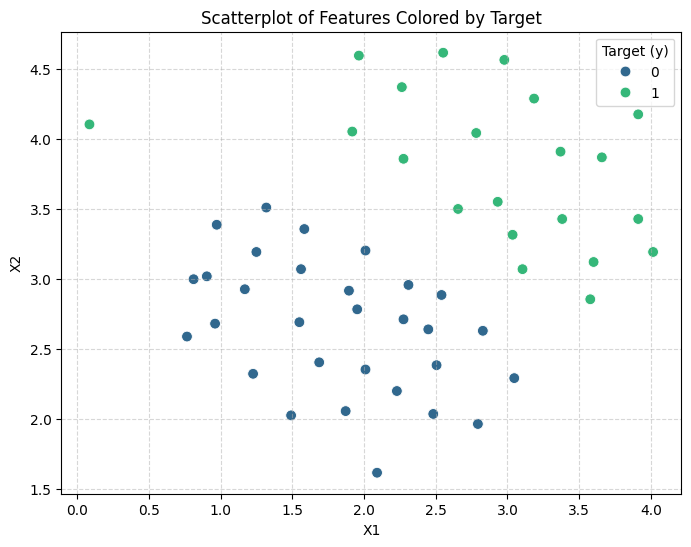

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='X1', y='X2', hue='y', palette='viridis', s=60)

plt.title('Scatterplot of Features Colored by Target')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend(title='Target (y)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Notice that there is one outlier positive example that sits apart from the others.  The classes are still linearly separable but it's a very tight fit.  We're going to train a linear support vector machine to learn the class boundary.

#### 5. LinearSVC
Declare a Linear SVC with the hyperparamenters:

```Python
LinearSVC(C=1, loss='hinge', max_iter=10000)
```

In [16]:
from sklearn.svm import LinearSVC

# Separate features and target from the DataFrame
X = df[['X1', 'X2']]
y = df['y']

# Declare and train the LinearSVC
svm_clf = LinearSVC(C=1, loss='hinge', max_iter=10000, random_state=42) 
svm_clf.fit(X, y)

#LinearSVC viene configurado por defecto con loss='squared_hinge' (pérdida de bisagra al cuadrado), que eleva el error al cuadrado y castiga de forma mucho más agresiva los puntos atípicos (outliers).
# Check training accuracy
print(f"Accuracy (C=1): {svm_clf.score(X, y):.4f}")

Accuracy (C=1): 0.9804


#### 6. Try the performance (score)
For the first experiment we'll use C=1 and see how it performs.

In [17]:
# Evaluate the model's accuracy on the dataset
score_c1 = svm_clf.score(X, y)
print(f"Model accuracy (C=1): {score_c1:.4f}")

Model accuracy (C=1): 0.9804


It appears that it mis-classified the outlier.

#### 7. Increase the value of C until you get a perfect classifier

In [18]:
from sklearn.svm import LinearSVC

# Test increasing values of C until accuracy reaches 1.0 (100%)
for c_val in [1, 10, 50, 100, 500]:
    svm_clf = LinearSVC(C=c_val, loss='hinge', max_iter=100000, random_state=42)
    svm_clf.fit(X, y)
    score = svm_clf.score(X, y)
    print(f"C = {c_val:<3} | Accuracy: {score:.4f}")
    
    if score == 1.0:
        print(f"\nPerfect classifier achieved at C = {c_val}")
        break

C = 1   | Accuracy: 0.9804
C = 10  | Accuracy: 0.9804
C = 50  | Accuracy: 0.9804
C = 100 | Accuracy: 0.9804
C = 500 | Accuracy: 1.0000

Perfect classifier achieved at C = 500


c:\Users\laras\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


This time we got a perfect classification of the training data, however by increasing the value of C we've created a decision boundary that is no longer a natural fit for the data.  We can visualize this by looking at the confidence level for each class prediction, which is a function of the point's distance from the hyperplane.

#### 8. Plot Decission Function
Get the `decision_function()` output for the first model. Plot a scatterplot with X1, X2 and a range of colors based on `decision_function()`

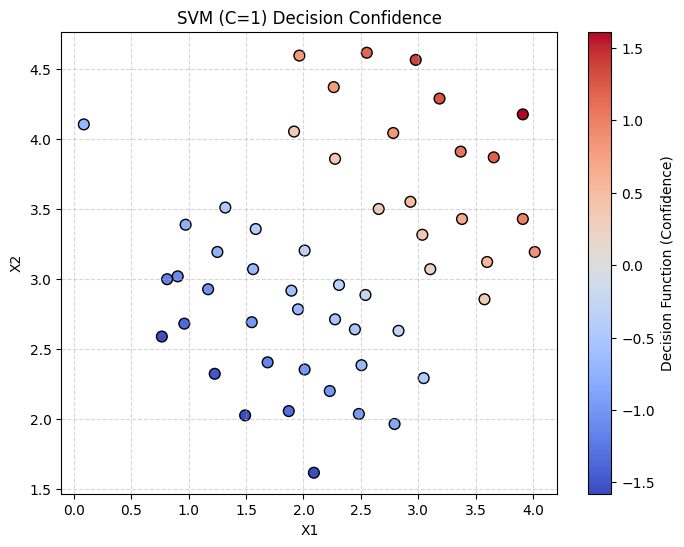

In [19]:
import matplotlib.pyplot as plt
from sklearn.svm import LinearSVC

# 1. Re-fit the first model (C=1) to make sure we use the right estimator
svm_c1 = LinearSVC(C=1, loss='hinge', max_iter=10000, random_state=42)
svm_c1.fit(X, y)

# 2. Get the decision_function() output (signed distance to the hyperplane)
df['SVM_Confidence'] = svm_c1.decision_function(X)

# 3. Plot the scatterplot colored by confidence level
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df['X1'],
    df['X2'],
    c=df['SVM_Confidence'],
    cmap='coolwarm',
    s=60,
    edgecolors='k'
)

plt.colorbar(scatter, label='Decision Function (Confidence)')
plt.title('SVM (C=1) Decision Confidence')
plt.xlabel('X1')
plt.ylabel('X2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

#### 9. Do the same with the second model

https://www.svm-tutorial.com/2015/06/svm-understanding-math-part-3/

#### 1. Load the data `ejer_1_data2.mat`

In [22]:
# Load the .mat file (adjust the path if it is inside a 'data/' folder)
data = loadmat('data/ejer_1_data2.mat')

# Inspect the dictionary keys to see the variable names stored inside
print(data.keys())

# Extract features (X) and target (y)
X = data['X']
y = data['y'].ravel()  # .ravel() converts y from shape (n, 1) to a 1D array (n,)

print("X shape:", X.shape)
print("y shape:", y.shape)

dict_keys(['__header__', '__version__', '__globals__', 'X', 'y'])
X shape: (863, 2)
y shape: (863,)


#### 2. Create a DataFrame with the features and target

In [23]:
import pandas as pd

# Generate feature column names dynamically (e.g., 'X1', 'X2')
feature_cols = [f'X{i+1}' for i in range(X.shape[1])]

# Create the DataFrame with features and append the target column
df = pd.DataFrame(X, columns=feature_cols)
df['y'] = y.ravel()

df.head()

,X1,X2,y
0,0.107143,0.603070,1
1,0.093318,0.649854,1
2,0.097926,0.705409,1
3,0.155530,0.784357,1
4,0.210829,0.866228,1


In [24]:
df.describe()

,X1,X2,y
count,863.000000,863.000000,863.000000
mean,0.503414,0.694304,0.556199
std,0.254967,0.158884,0.497120
min,0.044931,0.402632,0.000000
25%,0.292627,0.557018,0.000000
50%,0.512673,0.693713,1.000000
75%,0.699309,0.830409,1.000000
max,0.998848,0.988596,1.000000


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 863 entries, 0 to 862
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      863 non-null    float64
 1   X2      863 non-null    float64
 2   y       863 non-null    uint8  
dtypes: float64(2), uint8(1)
memory usage: 14.5 KB


#### 3. Plot a scatterplot with the data

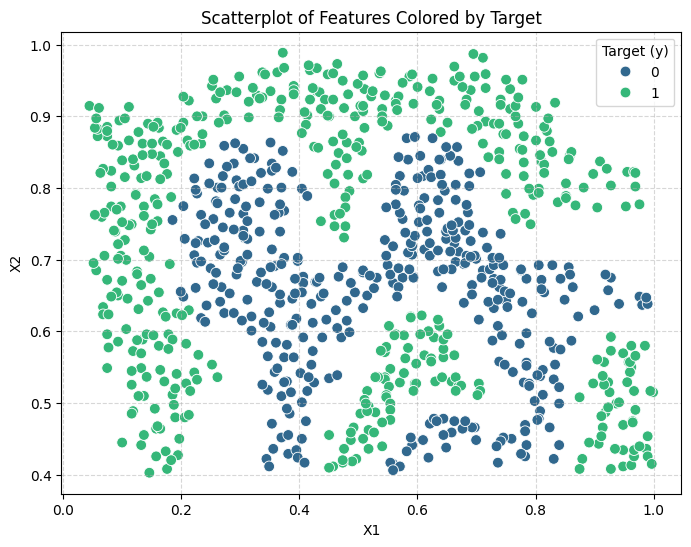

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='X1', y='X2', hue='y', palette='viridis', s=60)

plt.title('Scatterplot of Features Colored by Target')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend(title='Target (y)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

For this data set we'll build a support vector machine classifier using the built-in RBF kernel and examine its accuracy on the training data.  To visualize the decision boundary, this time we'll shade the points based on the predicted probability that the instance has a negative class label.  We'll see from the result that it gets most of them right.

#### 4. Declare a SVC with this hyperparameters
```Python
SVC(C=100, gamma=10, probability=True)
```


In [29]:
from sklearn.svm import SVC

# Separate features and target from the DataFrame
X = df[['X1', 'X2']]
y = df['y']



#### 5. Fit the classifier and get the score

In [30]:
# Declare and train the SVC (kernel='rbf' is the default in SVC)
#Radial Basis Function (Gaussian) kernel
svc = SVC(C=100, gamma=10, probability=True, random_state=42)
svc.fit(X, y)

# Check accuracy on the training data
print(f"Training Accuracy: {svc.score(X, y):.4f}")

Training Accuracy: 0.9699


c:\Users\laras\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


#### 6. Plot the scatter plot and probability of predicting 0 with a [sequential color](https://matplotlib.org/3.1.1/tutorials/colors/colormaps.html)

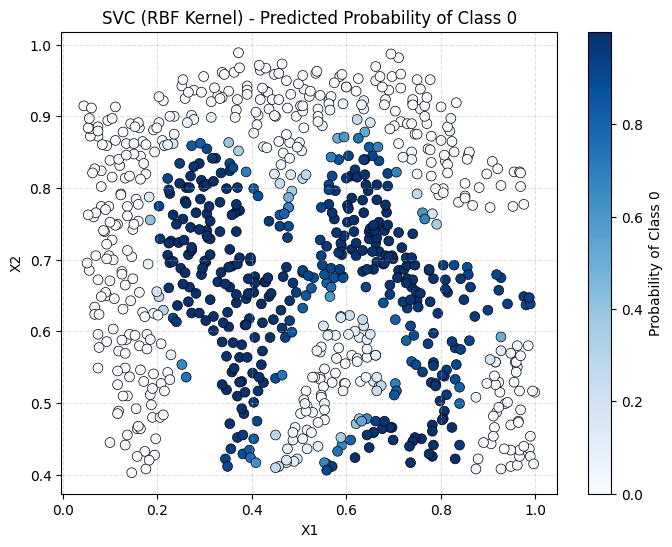

In [31]:
import matplotlib.pyplot as plt

# 1. Get the predicted probability of belonging to class 0 (negative class)
df['Prob_0'] = svc.predict_proba(X)[:, 0]

# 2. Plot the scatter plot with a sequential colormap (e.g., 'Blues' or 'viridis')
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df['X1'],
    df['X2'],
    c=df['Prob_0'],
    cmap='Blues',
    s=50,
    edgecolors='k',
    linewidths=0.5
)

plt.colorbar(scatter, label='Probability of Class 0')
plt.title('SVC (RBF Kernel) - Predicted Probability of Class 0')
plt.xlabel('X1')
plt.ylabel('X2')
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()